# 1. Khám phá & làm sạch dữ liệu

**Đồ án ADY201m — đề tài 4: YouTube Trending (VN).** Câu hỏi trọng tâm "thời điểm vàng":
đăng video trong **giờ hành chính** (08–17h, thứ 2–6, giờ VN) hay **giờ nghỉ** thì dễ lọt Top Trending hơn?

Notebook này kiểm tra chất lượng bảng phân tích `v_video_features` (PostgreSQL) và ghi lại các quyết định làm sạch.
Làm sạch được cài đặt trong SQL (`configs/features.sql`) dưới dạng **cờ** (không xoá dòng); notebook này kiểm chứng và giải thích từng cờ.
EDA bằng biểu đồ nằm ở `notebooks/3_EDA.Rmd` (RStudio).

Chạy: từ thư mục gốc repo, `uv run jupyter lab`, rồi mở notebook này. Cần Docker (Postgres) đang chạy.

In [1]:
import os, sys
from pathlib import Path

# Cho phép import src.* khi mở notebook từ thư mục notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, text

from src.utils.config import Config

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

url = (f"postgresql+psycopg2://{Config.POSTGRES_USER}:{Config.POSTGRES_PASSWORD}"
       f"@{Config.POSTGRES_HOST or 'localhost'}:{Config.POSTGRES_PORT or 5432}/{Config.POSTGRES_DB or 'youtube_trending_db'}")
engine = create_engine(url)

## 1. Đọc dữ liệu

`v_video_features` = cohort (video mới do job `uploads` phát hiện, theo dõi đủ 72 giờ) + feature + 2 nhãn + cờ làm sạch.
View tính độ phủ crawler cho từng video nên mất khoảng 30–40 giây.

In [2]:
with engine.connect() as con:
    con.execute(text("SET max_parallel_workers_per_gather = 0"))  # tránh lỗi shared memory trong container
    df = pd.read_sql(text("SELECT * FROM v_video_features"), con)

print(df.shape)
df.head(3)

(146057, 43)


,video_id,channel_id,published_at,release_at,release_at_vn,publish_hour_vn,publish_dow_vn,is_office_hours,category_id,category_title,duration_s,live_broadcast_content,is_live_or_premiere,definition,caption,default_audio_language,title_length,n_tags,channel_subscribers,channel_video_count,channel_view_count,channel_country,is_trending_main,hours_to_trending_main,best_rank_main,is_trending_category,hours_to_trending_category,best_rank_category,time_slot,is_weekend,day_part,slot_detail,subs_group,log10_subs,duration_group,is_short,flag_no_duration,flag_hidden_subs,flag_extreme_duration,coverage_24h,coverage_72h,flag_low_coverage,is_clean
0,8bKxpXeqYkk,UCQTMza9j2uwmvStsBpSXzGQ,2026-09-30 11:00:12+00:00,2026-09-30 11:00:12+00:00,2026-09-30 18:00:12,18,3,False,22,Mọi người và Blog,5448.0,none,False,hd,False,NaN,82,7,12300,184,3570595,VN,False,NaN,NaN,None,NaN,NaN,nghi,False,toi (18-24h),toi_ngay_thuong (17-24h),10k-100k,4.089940,>60 phut,False,False,False,False,0.833,0.917,False,True
1,cEBaXqY754g,UC8YW6FO4bJzh8IKJl3PtZqw,2026-09-26 18:46:38+00:00,2026-09-26 09:23:17+00:00,2026-09-26 16:23:17,16,6,False,20,Trò chơi,32033.0,none,True,hd,False,vi,16,25,675000,6170,602647497,VN,False,NaN,NaN,None,NaN,NaN,nghi,True,chieu (12-18h),cuoi_tuan,100k-1M,5.829304,>60 phut,False,False,False,True,0.958,0.736,False,False
2,8CTtb-WtNno,UCw4XpxkcuY-eY69_2pnIeHw,2026-10-04 18:00:35+00:00,2026-10-04 18:00:35+00:00,2026-10-05 01:00:35,1,1,False,22,Mọi người và Blog,12.0,none,False,hd,False,en-US,58,0,60800,3171,100741210,US,False,NaN,NaN,None,NaN,NaN,nghi,False,dem (0-6h),dem_sang_ngay_thuong (0-8h),10k-100k,4.783911,<=60s (Shorts),True,False,False,False,1.000,0.639,False,True


## 2. Hình dạng dữ liệu

In [3]:
print("Khoảng ra mắt (giờ VN):", df["release_at_vn"].min(), "->", df["release_at_vn"].max())
print("Số video:", len(df), "| số kênh:", df["channel_id"].nunique())
df.dtypes.to_frame("dtype").T

Khoảng ra mắt (giờ VN): 2026-09-24 23:53:02 -> 2026-10-20 08:00:09
Số video: 146057 | số kênh: 3607


,video_id,channel_id,published_at,release_at,release_at_vn,publish_hour_vn,publish_dow_vn,is_office_hours,category_id,category_title,duration_s,live_broadcast_content,is_live_or_premiere,definition,caption,default_audio_language,title_length,n_tags,channel_subscribers,channel_video_count,channel_view_count,channel_country,is_trending_main,hours_to_trending_main,best_rank_main,is_trending_category,hours_to_trending_category,best_rank_category,time_slot,is_weekend,day_part,slot_detail,subs_group,log10_subs,duration_group,is_short,flag_no_duration,flag_hidden_subs,flag_extreme_duration,coverage_24h,coverage_72h,flag_low_coverage,is_clean
dtype,str,str,"datetime64[us, UTC]","datetime64[us, UTC]",datetime64[us],int64,int64,bool,int64,str,float64,str,bool,str,bool,str,int64,int64,int64,int64,int64,str,bool,float64,float64,object,float64,float64,str,bool,str,str,str,float64,str,object,bool,bool,object,float64,float64,bool,bool


In [4]:
# Cỡ mẫu theo khung giờ × nhãn: kiểm tra mỗi nhóm có đủ positive không
pd.crosstab(df["time_slot"], df["is_trending_main"], margins=True)

is_trending_main,False,True,All
time_slot,,,
hanh_chinh,47245,205,47450
nghi,97819,788,98607
All,145064,993,146057


## 3. Giá trị thiếu

Giải thích các cột hay thiếu:
- `hours_to_trending_*`, `best_rank_*`: chỉ có giá trị khi video lên trending → thiếu là **bình thường**.
- `is_trending_category`: `NULL` với video ra mắt trước khi job `trending_category` chạy (09/10) → thiếu **có chủ ý**.
- `duration_s`: livestream chưa kết thúc. `channel_subscribers`: kênh ẩn số subscriber hoặc kênh tạm.
- `default_audio_language`, `definition`, `caption`: do chủ kênh không khai báo.

In [5]:
miss = (df.isna().mean() * 100).round(2)
miss = miss[miss > 0].sort_values(ascending=False).to_frame("% null")
miss

,% null
best_rank_main,99.32
hours_to_trending_main,99.32
best_rank_category,97.95
hours_to_trending_category,97.95
is_trending_category,42.94
default_audio_language,26.95
channel_country,12.93
duration_s,0.03
is_short,0.03
flag_extreme_duration,0.03


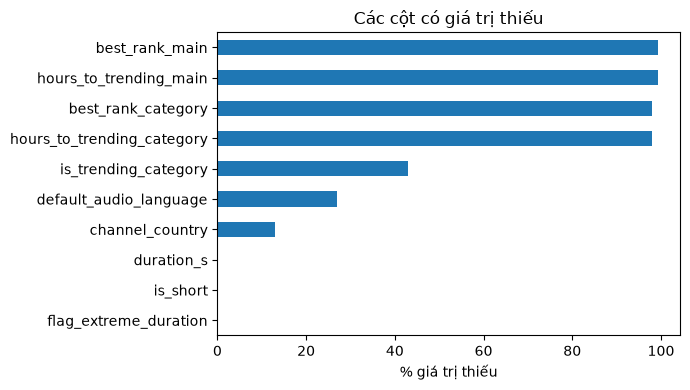

In [6]:
ax = miss["% null"].plot.barh(figsize=(7, 4))
ax.set_xlabel("% giá trị thiếu"); ax.set_title("Các cột có giá trị thiếu"); ax.invert_yaxis()
plt.tight_layout()

## 4. Trùng lặp và toàn vẹn

In [7]:
print("video_id trùng:", df["video_id"].duplicated().sum())
print("release_at thiếu:", df["release_at"].isna().sum())
# release_at khác published_at: livestream/premiere (YouTube đổi publishedAt thành lúc phát xong)
lech = (df["release_at"] != df["published_at"])
print("Video có release_at khác published_at (livestream/premiere):", lech.sum())

video_id trùng: 0
release_at thiếu: 0
Video có release_at khác published_at (livestream/premiere): 5301


Khoá ngoại, trùng khoá ở các bảng gốc đã kiểm tra bằng `configs/checks.sql` (Report 2): **0 lỗi**.

## 5. Ngoại lai

In [8]:
d = df["duration_s"]
print("Thời lượng = 0 giây:", (d == 0).sum())
print("Thời lượng > 3 giờ:", (d > 3 * 3600).sum())
print("Subscriber = 0:", (df["channel_subscribers"] == 0).sum())
d.describe(percentiles=[.01, .25, .5, .75, .99]).to_frame("duration_s").T

Thời lượng = 0 giây: 166
Thời lượng > 3 giờ: 1819
Subscriber = 0: 115


,count,mean,std,min,1%,25%,50%,75%,99%,max
duration_s,146012.0,1047.412329,3822.417144,0.0,7.0,27.0,75.0,591.0,12216.67,367321.0


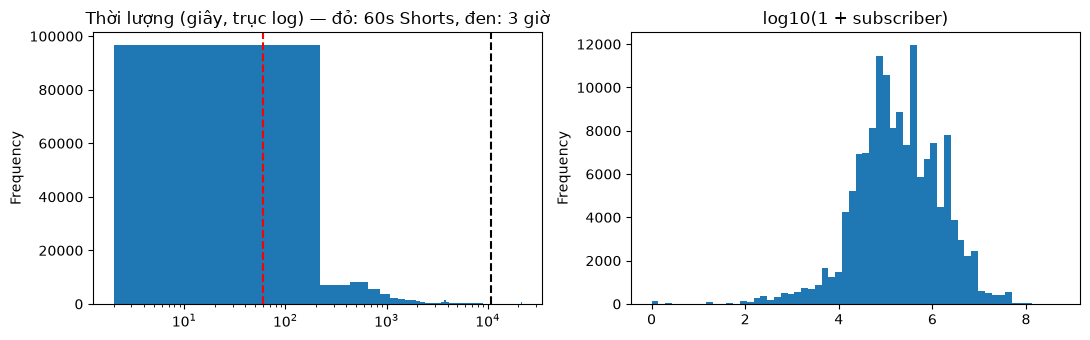

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
d[d > 0].clip(upper=6 * 3600).plot.hist(bins=100, logx=True, ax=axes[0])
axes[0].axvline(60, color="red", ls="--"); axes[0].axvline(3 * 3600, color="black", ls="--")
axes[0].set_title("Thời lượng (giây, trục log) — đỏ: 60s Shorts, đen: 3 giờ")
df["log10_subs"].plot.hist(bins=60, ax=axes[1])
axes[1].set_title("log10(1 + subscriber)")
plt.tight_layout()

## 6. Độ phủ của crawler — vấn đề chất lượng lớn nhất

Crawler trending chạy mỗi giờ nhưng máy có lúc tắt (máy tắt, Docker tắt). Nếu video lên trending đúng lúc crawler không chạy,
ta không thấy → **nhãn 0 sai**. `coverage_24h` / `coverage_72h` = tỉ lệ số giờ có lần chụp trending chính trong 24h / 72h đầu sau khi ra mắt.

In [10]:
with engine.connect() as con:
    runs = pd.read_sql(text("""
        SELECT DISTINCT date_trunc('hour', captured_at) AS h
        FROM trending_snapshots WHERE source = 'main' ORDER BY 1"""), con)

h = pd.to_datetime(runs["h"], utc=True)
full = pd.date_range(h.min(), h.max(), freq="h")
print(f"Số giờ trong khoảng crawl: {len(full)}, số giờ có chụp: {len(h)} ({len(h) / len(full):.0%})")

# Khoảng gián đoạn > 3 giờ
gaps = h.diff()
big = pd.DataFrame({"bat_dau": h.shift()[gaps > pd.Timedelta(hours=3)], "ket_thuc": h[gaps > pd.Timedelta(hours=3)]})
big["so_gio"] = (big["ket_thuc"] - big["bat_dau"]).dt.total_seconds() / 3600
print("Số khoảng gián đoạn > 3 giờ:", len(big))
big.sort_values("so_gio", ascending=False).head(10)

Số giờ trong khoảng crawl: 682, số giờ có chụp: 392 (57%)
Số khoảng gián đoạn > 3 giờ: 21


,bat_dau,ket_thuc,so_gio
344,2026-10-15 08:00:00+00:00,2026-10-19 06:00:00+00:00,94.0
391,2026-10-21 15:00:00+00:00,2026-10-23 01:00:00+00:00,34.0
216,2026-10-05 18:00:00+00:00,2026-10-06 11:00:00+00:00,17.0
290,2026-10-11 14:00:00+00:00,2026-10-12 05:00:00+00:00,15.0
322,2026-10-13 17:00:00+00:00,2026-10-14 08:00:00+00:00,15.0
186,2026-10-04 00:00:00+00:00,2026-10-04 13:00:00+00:00,13.0
241,2026-10-07 21:00:00+00:00,2026-10-08 07:00:00+00:00,10.0
63,2026-09-27 16:00:00+00:00,2026-09-28 00:00:00+00:00,8.0
255,2026-10-09 01:00:00+00:00,2026-10-09 09:00:00+00:00,8.0
268,2026-10-10 02:00:00+00:00,2026-10-10 08:00:00+00:00,6.0


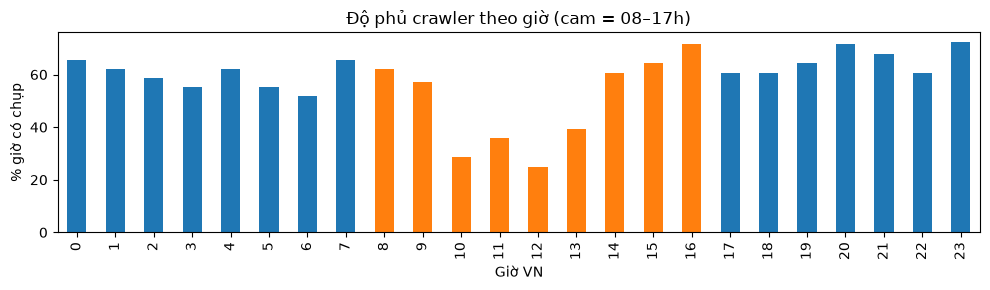

In [11]:
# Độ phủ theo giờ trong ngày (giờ VN): crawler hay vắng vào giờ nào?
cov = pd.Series(full.isin(h), index=full.tz_convert("Asia/Ho_Chi_Minh"))
by_hour = cov.groupby(cov.index.hour).mean() * 100
ax = by_hour.plot.bar(figsize=(10, 3), color=["tab:orange" if 8 <= x < 17 else "tab:blue" for x in by_hour.index])
ax.set_xlabel("Giờ VN"); ax.set_ylabel("% giờ có chụp"); ax.set_title("Độ phủ crawler theo giờ (cam = 08–17h)")
plt.tight_layout()

Độ phủ thấp nhất vào **10–13h** — nằm trong giờ hành chính. Video đăng giờ hành chính bị bỏ sót nhiều hơn ở những giờ đầu,
nên so sánh thô sẽ **thiên vị chống lại giờ hành chính**. Kiểm tra độ nhạy theo ngưỡng độ phủ:

In [12]:
rows = []
for thr in [0.0, 0.6, 0.8]:
    sub = df[(df["coverage_24h"] >= thr) & (df["coverage_72h"] >= thr)]
    rate = sub.groupby("time_slot")["is_trending_main"].agg(["size", "sum", "mean"])
    rows.append({"nguong_phu": thr, "so_video": len(sub),
                 "pct_hanh_chinh": round(rate.loc["hanh_chinh", "mean"] * 100, 3),
                 "pct_nghi": round(rate.loc["nghi", "mean"] * 100, 3),
                 "ti_le_nghi/hanh_chinh": round(rate.loc["nghi", "mean"] / rate.loc["hanh_chinh", "mean"], 2)})
pd.DataFrame(rows)

,nguong_phu,so_video,pct_hanh_chinh,pct_nghi,ti_le_nghi/hanh_chinh
0,0.0,146057,0.432,0.799,1.85
1,0.6,41081,0.795,1.305,1.64
2,0.8,11590,1.364,1.877,1.38


Dữ liệu càng sạch thì chênh lệch càng **thu hẹp nhưng không mất**. Chọn ngưỡng **0.6** cho `is_clean`
(cân bằng giữa độ tin cậy nhãn và cỡ mẫu); EDA trình bày cả 3 ngưỡng như phân tích độ nhạy.

## 7. Bảng quyết định làm sạch

In [13]:
quyet_dinh = pd.DataFrame([
    ("Livestream chưa có thời lượng (rỗng hoặc 0 giây)", "flag_no_duration", int(df["flag_no_duration"].sum()),
     "Loại khỏi is_clean", "Không biết thời lượng, không so sánh được"),
    ("Kênh ẩn subscriber / kênh tạm", "flag_hidden_subs", int(df["flag_hidden_subs"].sum()),
     "Loại khỏi is_clean", "Thiếu biến kiểm soát quy mô kênh"),
    ("Thời lượng > 3 giờ", "flag_extreme_duration", int(df["flag_extreme_duration"].fillna(False).sum()),
     "Loại khỏi is_clean", "Chủ yếu là bản ghi livestream dài, khác bản chất video thường"),
    ("Độ phủ crawler < 0.6 (24h hoặc 72h)", "flag_low_coverage", int(df["flag_low_coverage"].sum()),
     "Loại khỏi is_clean", "Nhãn 0 không đáng tin; độ phủ lệch theo giờ trong ngày"),
    ("Livestream / premiere", "release_at", int((df["release_at"] != df["published_at"]).sum()),
     "Giữ, dùng release_at", "YouTube đổi publishedAt; release_at = giờ khán giả xem được"),
    ("Like / comment bị ẩn", "(video_stats)", None, "Giữ NULL", "Không dùng làm feature ở câu hỏi này"),
], columns=["van_de", "cot", "so_dong", "xu_ly", "ly_do"])
quyet_dinh

,van_de,cot,so_dong,xu_ly,ly_do
0,Livestream chưa có thời lượng (rỗng hoặc 0 giây),flag_no_duration,211.0,Loại khỏi is_clean,"Không biết thời lượng, không so sánh được"
1,Kênh ẩn subscriber / kênh tạm,flag_hidden_subs,0.0,Loại khỏi is_clean,Thiếu biến kiểm soát quy mô kênh
2,Thời lượng > 3 giờ,flag_extreme_duration,1819.0,Loại khỏi is_clean,"Chủ yếu là bản ghi livestream dài, khác bản ch..."
3,Độ phủ crawler < 0.6 (24h hoặc 72h),flag_low_coverage,104976.0,Loại khỏi is_clean,Nhãn 0 không đáng tin; độ phủ lệch theo giờ tr...
4,Livestream / premiere,release_at,5301.0,"Giữ, dùng release_at",YouTube đổi publishedAt; release_at = giờ khán...
5,Like / comment bị ẩn,(video_stats),NaN,Giữ NULL,Không dùng làm feature ở câu hỏi này


## 8. Kết quả sau làm sạch

In [14]:
clean = df[df["is_clean"]]
tom_tat = (df.assign(tap=lambda x: x["is_clean"].map({True: "sau_lam_sach", False: "bi_loai"}))
             .groupby(["tap", "time_slot"])["is_trending_main"].agg(so_video="size", so_trending="sum", ti_le="mean"))
tom_tat["ti_le"] = (tom_tat["ti_le"] * 100).round(3)
print(f"Trước: {len(df):,} video → sau làm sạch: {len(clean):,} video ({len(clean) / len(df):.0%}), "
      f"{int(clean['is_trending_main'].sum())} positive")
tom_tat

Trước: 146,057 video → sau làm sạch: 40,307 video (28%), 397 positive


so_video  so_trending  ti_le
tap          time_slot                               
bi_loai      hanh_chinh     33379          118  0.354
             nghi           72371          478  0.660
sau_lam_sach hanh_chinh     14071           87  0.618
             nghi           26236          310  1.182

## 9. Xuất mẫu

In [15]:
mau = pd.concat([
    clean[clean["is_trending_main"]].sample(min(200, int(clean["is_trending_main"].sum())), random_state=42),
    clean[~clean["is_trending_main"]].sample(300, random_state=42),
])
out = ROOT / "data" / "processed" / "video_features_sample.csv"
mau.to_csv(out, index=False)
print("Đã ghi", out, mau.shape)

Đã ghi D:\Project\BanNH_QE210137_TRENDING_ANALYTICS\data\processed\video_features_sample.csv (500, 43)
